### Model Evaluation and Comparison


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST_PATH = DATA_DIR / "test.csv"
VECTORIZER_PATH = MODEL_DIR / "traditional_ml" / "tfidf_vectorizer.joblib"
TRADITIONAL_MODEL_PATH = MODEL_DIR / "traditional_ml" / "best_tfidf_model.joblib"
BERT_DIR = MODEL_DIR / "bert" / "fine-tuned"

for path in (TEST_PATH, VECTORIZER_PATH, TRADITIONAL_MODEL_PATH, BERT_DIR):
    if not path.exists():
        raise FileNotFoundError(f"Required file or folder not found: {path}")

test_df = pd.read_csv(TEST_PATH)
required_columns = {"clean_text", "sentiment"}
missing = required_columns - set(test_df.columns)
if missing:
    raise ValueError(f"Test data is missing columns: {sorted(missing)}")

test_df = test_df[["clean_text", "sentiment"]].copy()
test_df["clean_text"] = test_df["clean_text"].fillna("").astype(str)
test_df["sentiment"] = test_df["sentiment"].astype(str).str.strip().str.lower()
test_df = test_df[test_df["clean_text"].str.strip().ne("")].reset_index(drop=True)
if test_df.empty:
    raise ValueError("The test set has no non-empty reviews.")

print("Test reviews:", len(test_df))
print("Test labels:", sorted(test_df["sentiment"].unique()))


Test reviews: 1999
Test labels: ['negative', 'neutral', 'positive']


### Traditional TF-IDF model

In [2]:
vectorizer = joblib.load(VECTORIZER_PATH)
traditional_model = joblib.load(TRADITIONAL_MODEL_PATH)

X_test = vectorizer.transform(test_df["clean_text"])
traditional_predictions = traditional_model.predict(X_test)
y_true = test_df["sentiment"]

traditional_precision, traditional_recall, traditional_f1, _ = (
    precision_recall_fscore_support(
        y_true, traditional_predictions, average="macro", zero_division=0
    )
)
traditional_accuracy = accuracy_score(y_true, traditional_predictions)

print("Traditional TF-IDF model")
print(classification_report(y_true, traditional_predictions, zero_division=0))


d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Tryin

Traditional TF-IDF model
              precision    recall  f1-score   support

    negative       0.68      0.65      0.67       336
     neutral       0.34      0.39      0.37       229
    positive       0.90      0.89      0.90      1434

    accuracy                           0.79      1999
   macro avg       0.64      0.64      0.64      1999
weighted avg       0.80      0.79      0.80      1999



### Fine-tuned BERT model

In [3]:
tokenizer = AutoTokenizer.from_pretrained(str(BERT_DIR))
bert_model = AutoModelForSequenceClassification.from_pretrained(str(BERT_DIR))

label_path = BERT_DIR / "label_encoder_classes.txt"
if label_path.exists():
    bert_labels = label_path.read_text(encoding="utf-8").splitlines()
else:
    bert_labels = [
        bert_model.config.id2label[i]
        for i in range(bert_model.config.num_labels)
    ]

if len(bert_labels) != bert_model.config.num_labels:
    raise ValueError("BERT label list does not match the model output size.")
if set(y_true.unique()) - set(bert_labels):
    raise ValueError("Test labels do not match the labels used to train BERT.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
bert_model.eval()

bert_predictions = []
batch_size = 32
texts = test_df["clean_text"].tolist()
with torch.no_grad():
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(
            texts[start:start + batch_size],
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)
        logits = bert_model(**batch).logits
        bert_predictions.extend(logits.argmax(dim=1).cpu().tolist())

bert_predictions = [bert_labels[i] for i in bert_predictions]
bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(
    y_true, bert_predictions, average="macro", zero_division=0
)
bert_accuracy = accuracy_score(y_true, bert_predictions)

print("Fine-tuned BERT model")
print(classification_report(y_true, bert_predictions, zero_division=0))


W1024 07:46:08.503000 26488 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Fine-tuned BERT model
              precision    recall  f1-score   support

    negative       0.77      0.71      0.74       336
     neutral       0.38      0.34      0.36       229
    positive       0.90      0.94      0.92      1434

    accuracy                           0.83      1999
   macro avg       0.68      0.66      0.67      1999
weighted avg       0.82      0.83      0.83      1999



### Compare results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Fine-tuned BERT,0.8294,0.6845,0.6628,0.6729
1,Traditional TF-IDF,0.7939,0.6428,0.6434,0.6425


Saved: d:\My_Project\Analyse\mobile-review-sentiment-analysis\outputs\evaluation\final_model_comparison.csv


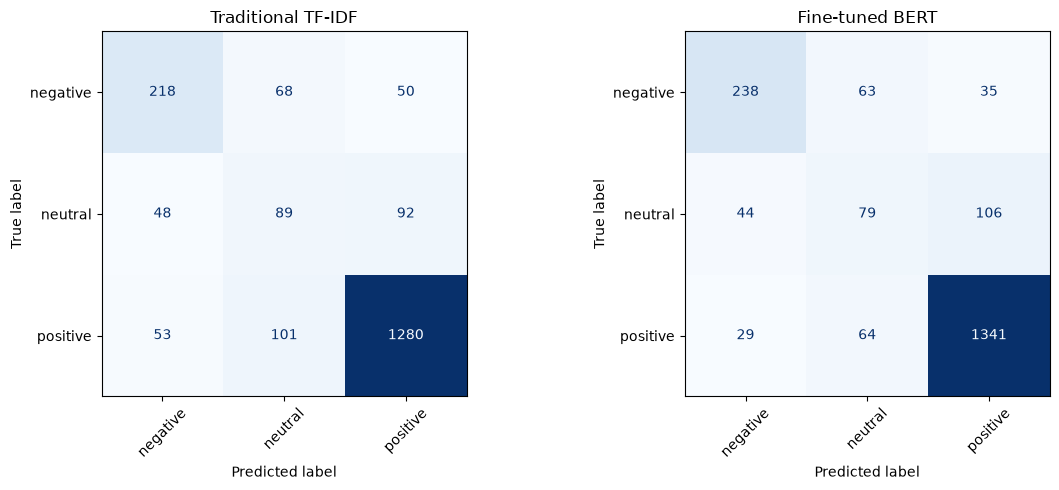

In [4]:
comparison = pd.DataFrame([
    {
        "Model": "Traditional TF-IDF",
        "Accuracy": traditional_accuracy,
        "Macro Precision": traditional_precision,
        "Macro Recall": traditional_recall,
        "Macro F1": traditional_f1,
    },
    {
        "Model": "Fine-tuned BERT",
        "Accuracy": bert_accuracy,
        "Macro Precision": bert_precision,
        "Macro Recall": bert_recall,
        "Macro F1": bert_f1,
    },
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(comparison.round(4))
comparison_path = OUTPUT_DIR / "final_model_comparison.csv"
comparison.to_csv(comparison_path, index=False)
print("Saved:", comparison_path)

labels = sorted(y_true.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, predictions, title in [
    (axes[0], traditional_predictions, "Traditional TF-IDF"),
    (axes[1], bert_predictions, "Fine-tuned BERT"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_true, predictions, labels=labels, xticks_rotation=45,
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()
